# 05 小程序 - 基础加强（续）


本篇是微信小程序基础第 05 天，承接 04 的自定义组件，按原课顺序展开：npm 与 Vant Weapp → API Promise 化 → MobX 全局数据共享 → 普通分包、独立分包与预下载 → 自定义 tabBar 案例。

原讲义标题仍为《小程序 - 基础加强》，文件名用“（续）”区分同主题的两天。资料来自[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)的微信小程序基础 `day05.rar`：100 页正文讲义、4 页目标讲义、`学习目标.txt`、`代码.rar` 和 `资料.rar`。正文前 57 页重复了第 04 天的组件内容，本篇从第 59 页开始整理新增内容；前置概念可回看同目录的 `04-小程序基础加强.ipynb`。

`资料.rar` 是起始项目 `mp_05`，`代码.rar` 是完成版，另有 `test/01.html`、`01.css` 演示 CSS 变量。完成版同时包含依赖源码 `node_modules` 与构建结果 `miniprogram_npm`。

| 配套文件或目录 | 本篇用途 |
| --- | --- |
| `package.json`、`app.json`、`app.wxss` | 安装依赖、引用 Vant 组件、定制主题 |
| `app.js`、`pages/home/home.*` | 初始化 Promise API，点击按钮请求数据 |
| `store/store.js`、`pages/message/message.*` | 创建共享 Store，页面操作 `numA` |
| `components/numbers/numbers.*` | 组件操作 `numB`，与页面共享求和数据 |
| `pkgA`、`pkgB` | 普通分包与独立分包练习 |
| `custom-tab-bar/index.*` | Vant tabBar、选中状态与消息徽标 |

在微信开发者工具中导入小程序项目时使用自己的 AppID；配套基础库版本和项目配置属于课程环境。以下命令在 `mp_05` 根目录使用，代码片段合并到标明的文件中，保留其他已有配置。所有示例放在 Markdown 围栏中，不使用执行单元。


## 一、使用 npm 包与 Vant Weapp

### 1. 小程序对 npm 的支持与限制

npm 用来安装第三方 JavaScript 包，但小程序的运行环境不等同于 Node.js 或浏览器。原课列出三类不支持的依赖：

1. 依赖 Node.js 内置库的包。
2. 依赖浏览器内置对象的包。
3. 依赖 C++ 插件的包。

因此，安装成功不等于能够在小程序中使用，需要选择适配小程序的包。本课选择 Vant Weapp 提供界面组件，用其他专门的小程序包处理 Promise API 和状态管理。

### 2. Vant Weapp 是什么

Vant Weapp 是有赞前端团队开源的小程序 UI 组件库，使用 MIT 许可协议。课程文档为 [Vant Weapp](https://youzan.github.io/vant-weapp/)。本篇沿用课程版本 `@vant/weapp@1.3.3`，与配套组件路径、事件和徽标字段一致。


### 3. 安装并构建 Vant

原课分三步：npm 安装 → 构建 npm 包 → 修改 `app.json`。

在 `mp_05` 根目录操作，安装指定版本：

```bash
npm install --save @vant/weapp@1.3.3
```

操作补充：如果从 `资料.rar` 起步、根目录尚无 `package.json`，先在同一目录运行 `npm init -y`，再安装依赖。完成版已有该文件和依赖目录，不必再次初始化。

安装后，在微信开发者工具中执行“工具 → 构建 npm”。开发者工具把可供小程序使用的依赖构建到 `miniprogram_npm`，不要把 `node_modules` 当成构建后的组件引用目录。

配套 `project.config.json` 中启用了 `setting.nodeModules: true`，并启用 ES6 编译。若当前工具版本需要打开“使用 npm 模块”，在项目本地设置中检查该项，再进行构建。

起始 `app.json` 有 `"style": "v2"`，完成版移除了该字段；按本课 Vant 配置去掉这一项，同时保留页面、窗口与 tabBar 配置。然后添加下一节的 `usingComponents`。

验证顺序：检查 `package.json` 中的依赖 → npm 构建成功 → `miniprogram_npm/@vant/weapp` 中有对应组件 → 页面能渲染按钮。

资料说明：完成版 `package.json` 使用 `^1.3.3` 等版本范围，`package-lock.json` 锁定的实际版本为 `1.3.3`；本篇命令显式指定课程版本。


### 4. 引用并使用 Vant 按钮

在 `app.json` 根级 `usingComponents` 中添加按钮，以下是字段片段，不替换整个文件：

```json
{
  "usingComponents": {
    "van-button": "@vant/weapp/button/index"
  }
}
```

在 `pages/home/home.wxml` 中使用：

```xml
<van-button type="primary">按钮</van-button>
<van-button type="danger">按钮</van-button>
```

`type="primary"` 是主要按钮，`type="danger"` 是危险操作配色按钮。全局注册后，在本课页面和普通自定义组件中都可使用同一标签。

本课先让按钮显示出来，随后再给主要按钮绑定 `getInfo` 事件。如果构建成功但组件找不到，核对组件路径、注册位置与 `miniprogram_npm` 是否为当前依赖构建的结果。


### 5. CSS 变量为什么能用于主题定制

Vant Weapp 使用 CSS 变量定制主题。变量以 `--` 开头，定义后通过 `var(--变量名)` 使用。

配套 `代码/test/01.html` 用网页先演示这个概念，核心样式为：

```css
html {
  /* 定义CSS变量 */
  --main-color: #C00000;
}

.box1, .box2 {
  /* background-color: #C00000; */
  background-color: var(--main-color);
}

.box3 {
  /* color: #C00000; */
  color: var(--main-color);
}
```

网页的两个容器中都使用 `.box1`、`.box2`、`.box3`。修改 `--main-color` 后，前两个盒子的背景色与第三个盒子的文字色一起改变，避免每处都写一遍颜色。

这是讲解变量的网页示例。小程序中下一步把 Vant 已支持的变量放到 `app.wxss` 的 `page` 规则里。原课给出的参考是 [MDN CSS 自定义属性](https://developer.mozilla.org/zh-CN/docs/Web/CSS/Using_CSS_custom_properties)。


### 6. 定制全局按钮主题

在 `app.wxss` 中加入下面的 `page` 规则。讲义先改 `danger` 的背景和边框，配套源码同时改了 `primary`：

```css
page {
  --button-danger-background-color: #C00000;
  --button-danger-border-color: #D60000;

  --button-primary-background-color: #13A7A0;
  --button-primary-border-color: #15B4AA;
}
```

| 变量 | 作用 |
| --- | --- |
| `--button-danger-background-color` | danger 按钮背景 |
| `--button-danger-border-color` | danger 按钮边框 |
| `--button-primary-background-color` | primary 按钮背景 |
| `--button-primary-border-color` | primary 按钮边框 |

重新编译后，首页两个按钮应使用课程设置的红色和青绿色；其他引用同类 Vant 按钮的本课页面也使用这些主题变量。

变量名必须与组件库支持的名称一致。原课给出的变量列表参考为 [Vant var.less](https://github.com/youzan/vant-weapp/blob/dev/packages/common/style/var.less)，配套依赖的 `lib/common/style/var.wxss` 也可用于核对课程版本。


## 二、API Promise 化

### 1. 回调写法的问题

原课用 `wx.request` 说明异步 API 的回调形式：

```javascript
wx.request({
  method: '',
  url: '',
  data: {},
  success: () => {}, // 请求成功的回调函数
  fail: () => {}, // 请求失败的回调函数
  complete: () => {} // 请求完成的回调函数
})
```

这是讲义展示的调用结构，空 `method`、`url` 不是可发请求的配置。当后续异步操作依赖前一次结果时，连续嵌套回调会使代码难读、难维护。

API Promise 化通过额外配置，将本课使用的回调型异步 API 包装为基于 Promise 的调用方式，以便使用 `async/await`。课程使用 `miniprogram-api-promise` 实现这一步。


### 2. 安装并在 app.js 初始化

在 `mp_05` 根目录安装原课版本：

```bash
npm install --save miniprogram-api-promise@1.0.4
```

新增依赖后重新“构建 npm”。在入口文件 `app.js` 中、原有 `App({...})` 前增加配套代码：

```javascript
//app.js
import { promisifyAll } from 'miniprogram-api-promise'

const wxp = wx.p = {}
promisifyAll(wx, wxp)
```

`wxp` 和 `wx.p` 指向同一个空对象，`promisifyAll(wx, wxp)` 把包装后的 API 放到该对象上。入口初始化只调用一次，页面随后使用 `wx.p.request`；原有 `wx.request` 仍是原入口。

保留文件中已有的 `App({...})`。课程重点是顶部这段初始化，不需要照搬配套模板中的登录及旧用户信息示例。


### 3. 调用 Promise 化后的 request

`pages/home/home.wxml` 的完成版给主要按钮绑定 `getInfo`：

```xml
<!--pages/home/home.wxml-->
<van-button type="primary" bindtap="getInfo">按钮</van-button>
<van-button type="danger">按钮</van-button>
```

在 `pages/home/home.js` 的 `Page` 对象中定义配套方法：

```javascript
Page({
  async getInfo() {
    const {data: res} = await wx.p.request({
      method: 'GET',
      url: 'https://www.escook.cn/api/get',
      data: {
        name: 'zs',
        age: 20
      }
    })
    console.log(res)
  }
})
```

`async` 让方法中能使用 `await`。`wx.p.request` 返回 Promise，等待后得到请求响应对象；`const {data: res}` 从响应对象取出 `data`，并将它命名为 `res`，然后输出响应正文。

请求参数沿用课程：GET 请求 `https://www.escook.cn/api/get`，发送 `name: 'zs'`、`age: 20`。讲义把绑定按钮写成 `danger`，源码用 `primary`，请求方法相同；本篇按实际源码保留按钮类型。

练习时点击首页主要按钮，查看开发者工具网络面板和控制台。检查 AppID 对应的 request 合法域名配置、当前网络和接口返回；不要把响应正文 `res` 与整个响应对象混淆。

补充：`await` 不会自动处理失败。原课此示例没有捕获异常，实际请求失败时还需要在调用处处理拒绝结果。本篇保留课程核心写法，不把预期响应写成已实测结果。


## 三、用 MobX 实现全局数据共享

全局数据共享也称状态管理，用来解决多个页面、组件使用同一组数据的问题。原课提到 Vuex、Redux、MobX，本节具体使用适配小程序的 MobX。

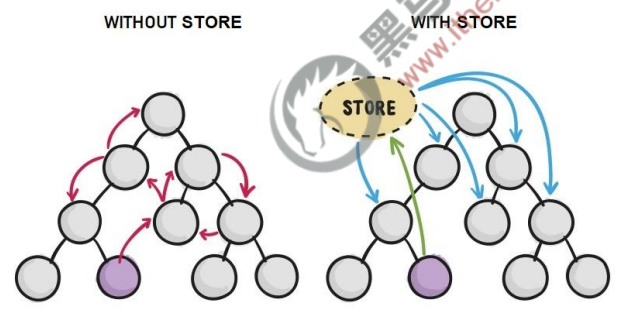

页面和组件绑定同一个 Store，数据修改后由绑定层同步到界面，不必逐层手工传递。这里将 `numA`、`numB` 和求和结果 `sum` 同时展示在消息页面与 numbers 组件中。

| 包 | 本课职责 |
| --- | --- |
| `mobx-miniprogram` | 创建可观察的 Store，定义修改数据的 action |
| `mobx-miniprogram-bindings` | 把 Store 的字段和方法绑定到页面或组件 |

`Store` 是保存共享状态的对象；`observable` 让状态可被追踪；`action` 表示本课专门修改 Store 数据的方法。


### 1. 安装 MobX 相关包

在 `mp_05` 根目录执行原课命令：

```bash
npm install --save mobx-miniprogram@4.13.2 mobx-miniprogram-bindings@1.2.1
```

讲义要求安装后删除项目内的旧 `miniprogram_npm` 生成目录，再重新“构建 npm”。这是清理构建结果并重新生成的课程操作，不是删除组件源码、`node_modules` 或整个项目。

到这里，配套锁定的依赖版本为：

| 包 | 课程版本 |
| --- | --- |
| `@vant/weapp` | `1.3.3` |
| `miniprogram-api-promise` | `1.0.4` |
| `mobx-miniprogram` | `4.13.2` |
| `mobx-miniprogram-bindings` | `1.2.1` |

构建成功后，再添加 Store 和绑定代码，避免把依赖未构建造成的模块错误误认为 MobX 数据问题。


### 2. 创建 Store

在项目根目录创建 `store/store.js`。这一阶段先保留讲义的两个数值、计算属性与两个 action：

```javascript
// 在这个 JS 文件中，专门来创建 Store 的实例对象
import { observable, action } from 'mobx-miniprogram'

export const store = observable({
  // 数据字段
  numA: 1,
  numB: 2,
  // 计算属性
  get sum() {
    return this.numA + this.numB
  },
  // actions 函数，专门来修改 store 中数据的值
  updateNum1: action(function (step) {
    this.numA += step
  }),
  updateNum2: action(function (step) {
    this.numB += step
  })
})
```

| 成员 | 含义 |
| --- | --- |
| `numA`、`numB` | 初始共享数值 `1` 和 `2` |
| `get sum()` | 计算属性，返回 `numA + numB` |
| `updateNum1(step)` | 根据步长修改 `numA` |
| `updateNum2(step)` | 根据步长修改 `numB` |

模板把 `sum` 当数据字段读取，不是调用 `sum()`。步长 `1` 表示加 1，`-1` 表示减 1。

`store` 通过 `export` 导出，消息页面和 numbers 组件均从这个文件导入同一个实例。不要在每个页面各建一份 Store，否则无法复现共享效果。完成版还添加了 `activeTabBarIndex` 及其 action，用于最后的 tabBar 案例。


### 3. 把 Store 成员绑定到页面

在 `pages/message/message.js` 导入绑定函数与 Store。页面加载时创建绑定，并保存返回对象；卸载时清理：

```javascript
import { createStoreBindings } from 'mobx-miniprogram-bindings'
import { store } from '../../store/store'

Page({
  onLoad: function (options) {
    this.storeBindings = createStoreBindings(this, {
      store,
      fields: ['numA', 'numB', 'sum'],
      actions: ['updateNum1']
    })
  },

  onUnload: function () {
    this.storeBindings.destroyStoreBindings()
  }
})
```

`createStoreBindings(this, {...})` 的目标是当前页面。`fields` 把 `numA`、`numB`、`sum` 同步到页面数据，`actions` 把 `updateNum1` 映射到页面实例，所以页面可以调用 `this.updateNum1(...)`。

> 源码校对：配套 `message.js` 的卸载方法误写成 `detroyStoreBindings()`，缺少字母 `s`。讲义第 74 页与包内 README、实现均为 `destroyStoreBindings()`。上面使用正确写法；若直接练习完成版，需要修正这一处，否则页面卸载时会调用不存在的方法。

绑定的创建与清理分别属于 `onLoad` 和 `onUnload`，不要每次 `onShow` 都重新建立一份绑定。


### 4. 在消息页面读取数据、调用 action

`pages/message/message.wxml` 使用绑定后的字段，并通过 `data-step` 区分加减按钮：

```xml
<!--pages/message/message.wxml-->
<view>{{numA}} + {{numB}} = {{sum}}</view>
<van-button type="primary" bindtap="btnHandler1" data-step="{{1}}">numA + 1</van-button>
<van-button type="danger" bindtap="btnHandler1" data-step="{{-1}}">numA - 1</van-button>

<view>~~~~~~</view>

<my-numbers></my-numbers>
```

在 `pages/message/message.js` 的 `Page` 对象中添加配套事件函数：

```javascript
Page({
  btnHandler1(e) {
    // console.log(e)
    this.updateNum1(e.target.dataset.step)
  }
})
```

`data-step="{{1}}"`、`data-step="{{-1}}"` 传递数值步长，`e.target.dataset.step` 是配套源码的读取方式。事件函数调用 Store action，而不是只用页面自己的 `setData` 改一份显示数据。

WXML 的 `<my-numbers>` 会在下一步注册并创建。初始应看到 `1 + 2 = 3`；点击 `numA + 1` 后应变成 `2 + 2 = 4`，点击 `numA - 1` 则减少一个步长。

补充：事件发生在嵌套节点时，`target` 与绑定节点不一定相同；本课代码按原写法保留，排查取不到步长时可核对 `e.currentTarget.dataset.step`。


### 5. 把 Store 成员绑定到组件

创建 `components/numbers/numbers` 组件，在 `app.json` 的 `usingComponents` 中加入：

```json
{
  "usingComponents": {
    "van-button": "@vant/weapp/button/index",
    "my-numbers": "./components/numbers/numbers"
  }
}
```

`components/numbers/numbers.json` 必须声明它是组件：

```json
{
  "component": true,
  "usingComponents": {}
}
```

在 `components/numbers/numbers.js` 导入 `storeBindingsBehavior` 和同一个 Store，配套代码为：

```javascript
// components/numbers/numbers.js
import { storeBindingsBehavior } from 'mobx-miniprogram-bindings'
import { store } from '../../store/store'

Component({
  behaviors: [storeBindingsBehavior],
  storeBindings: {
    // 数据源
    store,
    fields: {
      numA: 'numA',
      numB: 'numB',
      sum: 'sum'
    },
    actions: {
      updateNum2: 'updateNum2'
    }
  },
  /**
   * 组件的属性列表
   */
  properties: {

  },

  /**
   * 组件的初始数据
   */
  data: {

  },

  /**
   * 组件的方法列表
   */
  methods: {
    btnHandler2(e) {
      this.updateNum2(e.target.dataset.step)
    }
  }
})
```

`behaviors: [storeBindingsBehavior]` 应用了 04 的代码共享机制，由绑定库处理组件绑定。`storeBindings` 中指定数据源、字段与 action；它不是组件的普通 `data`。

对象映射中，左边是组件使用的名称，右边是 Store 的成员名。这里名称相同，例如 `numA: 'numA'`、`updateNum2: 'updateNum2'`。

补充校对：配套绑定库在 `attached` 中建立数据绑定，在 `detached` 中销毁绑定；本课这种 behavior 方式不需要再照抄页面的手工绑定流程。


### 6. 理解组件 fields 的三种写法

讲义第 76 页用三种写法分别绑定三个字段，`storeBindings` 的相关结构如下：

```javascript
import { storeBindingsBehavior } from 'mobx-miniprogram-bindings'
import { store } from '../../store/store'

Component({
  behaviors: [storeBindingsBehavior],
  storeBindings: {
    store,
    fields: {
      numA: () => store.numA,
      numB: (store) => store.numB,
      sum: 'sum'
    },
    actions: {
      updateNum2: 'updateNum2'
    }
  }
})
```

| 写法 | 取值来源 |
| --- | --- |
| `numA: () => store.numA` | 回调读取导入的 Store |
| `numB: (store) => store.numB` | 回调使用绑定层传入的 Store |
| `sum: 'sum'` | 字符串映射到 Store 的同名成员 |

配套 numbers 完成版统一用字符串映射，前一节已保留实际源码；此处保留讲义的三种写法，便于理解绑定参数。


### 7. 在组件中使用共享状态

`components/numbers/numbers.wxml`：

```xml
<!--components/numbers/numbers.wxml-->
<view>{{numA}} + {{numB}} = {{sum}}</view>
<van-button type="primary" bindtap="btnHandler2" data-step="{{1}}">numB + 1</van-button>
<van-button type="danger" bindtap="btnHandler2" data-step="{{-1}}">numB - 1</van-button>
```

`btnHandler2` 位于组件 `methods`，通过 `this.updateNum2(step)` 修改 Store 的 `numB`。

消息页面已经插入 `<my-numbers></my-numbers>`，因此同一页上可看到两组等式：上面由页面显示，下面由组件显示。

验证共享效果：

1. 先确认两组都显示 `1 + 2 = 3`。
2. 点击页面的 `numA + 1`，两组都应更新为 `2 + 2 = 4`。
3. 点击组件的 `numB + 1`，两组都应更新为 `2 + 3 = 5`。
4. 分别点减号，确认更新的是 Store 中的同一组数值。

配套绑定库会合并数据更新并同步到视图；观察界面更新后的结果，不要把某一个页面的显示字段当成另一份独立共享状态。


## 四、分包

### 1. 分包要解决什么问题

没有分包时，所有页面和资源一起打包，项目变大后会影响首次启动的下载时间。分包按功能把完整项目划分为子包，在需要时加载；原课还指出，它有助于多个团队分工开发。

分包后的结构由一个主包和多个分包组成：

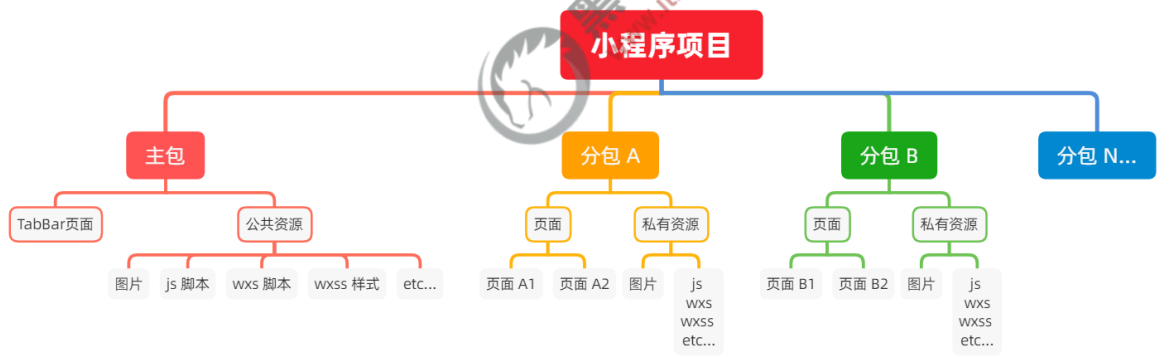

主包通常放启动页面、tabBar 页面和普通分包都需要的公共资源；分包放当前功能相关的页面和私有资源。

### 2. 加载规则

1. 正常启动时先下载主包并启动主包页面。
2. 进入某个分包的页面时，下载对应分包，完成后显示页面。
3. tabBar 页面必须放在主包中；非 tabBar 页面可以按功能划分到分包。

原课当时给出的体积限制：主包加所有分包合计不超过 `16M`，单个主包或分包不超过 `2M`。这是讲义所处版本的限额；实际开发应以当前[微信分包文档](https://developers.weixin.qq.com/miniprogram/dev/framework/subpackages.html)及开发者工具的校验结果为准。


### 3. 按配套目录配置普通分包

完成版的目录结构是：

```text
mp_05/
├─ app.js、app.json、app.wxss
├─ pages/
│  ├─ home/home.*
│  ├─ message/message.*
│  └─ contact/contact.*
├─ pkgA/
│  └─ pages/
│     ├─ cat/cat.*
│     └─ dog/dog.*
├─ pkgB/
│  └─ pages/
│     └─ apple/apple.*
├─ images/
├─ store/
└─ custom-tab-bar/
```

从起始项目练习时，在 `app.json` 中声明分包，再为路径创建页面文件。普通分包阶段的配置如下，保留其他根级配置：

```json
{
  "pages": [
    "pages/home/home",
    "pages/message/message",
    "pages/contact/contact"
  ],
  "subpackages": [
    {
      "root": "pkgA",
      "name": "p1",
      "pages": [
        "pages/cat/cat",
        "pages/dog/dog"
      ]
    },
    {
      "root": "pkgB",
      "name": "p2",
      "pages": [
        "pages/apple/apple"
      ]
    }
  ]
}
```

| 字段 | 含义 |
| --- | --- |
| 根级 `pages` | 主包页面，相对于小程序根目录 |
| `subpackages` | 分包配置数组 |
| `root` | 分包的根目录 |
| 分包 `pages` | 页面路径，相对于该分包根目录 |
| `name` | 可选的分包别名，本例为 `p1`、`p2` |

例如 `pkgA` 中的 `pages/cat/cat`，完整页面路径是 `/pkgA/pages/cat/cat`，不能在分包 `pages` 中再次拼接 `pkgA/`。

资料差异：讲义第 85 页用 `packageA`、`packageB` 与较简化的页面路径演示；配套项目实际使用 `pkgA`、`pkgB` 和四文件页面目录，`pkgB` 只有 apple 页面。本篇按实际文件写，避免引用不存在的目录。此处先演示普通分包，完成版的 `pkgB` 还配置了下一节的独立分包。


### 4. 打包原则与引用原则

原课的打包原则：

1. 按 `subpackages` 配置划分分包，其余目录归入主包。
2. 最外层 `pages` 定义主包自己的页面。
3. tabBar 页面必须在主包。
4. 分包之间不能互相嵌套。

普通分包的资源引用方向：

| 引用方向 | 原课规则 |
| --- | --- |
| 主包 → 分包私有资源 | 不能引用 |
| 普通分包 A → 普通分包 B 私有资源 | 不能引用 |
| 普通分包 → 主包公共资源 | 可以引用 |

多个普通分包需要的公共图片、脚本或样式应放在主包；只属于某个分包的资源留在对应分包内。

操作补充：配套分包页面只显示自身路径文字，没有现成的跳转按钮。可以在主包页面临时加入一个导航标签验证普通分包路由：

```xml
<navigator url="/pkgA/pages/cat/cat">进入 pkgA 的 cat 页面</navigator>
```

这个目标是普通页面，使用普通导航；tabBar 页面继续使用 `switchTab`。运行时查看包信息与页面路径，确认 cat 页面被识别为 `pkgA` 的页面。

上述引用规则是原课讨论的常规资源边界，不意味着从主包不能导航到分包页面。


### 5. 独立分包

独立分包可以不下载主包而单独运行，适合功能足够独立、需要直接作为入口的页面。普通分包从页面入口启动时仍依赖主包；独立分包降低这种入口的下载依赖。一个小程序可有多个独立分包。

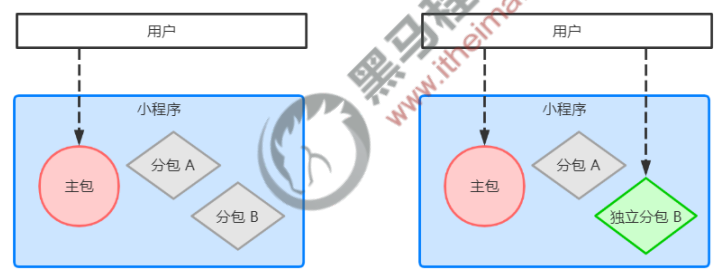

在 `app.json` 的对应分包对象中加 `"independent": true`。配套完成版把 `pkgB` 设为独立分包：

```json
{
  "subpackages": [
    {
      "root": "pkgA",
      "name": "p1",
      "pages": [
        "pages/cat/cat",
        "pages/dog/dog"
      ]
    },
    {
      "root": "pkgB",
      "name": "p2",
      "pages": [
        "pages/apple/apple"
      ],
      "independent": true
    }
  ]
}
```

`independent` 放在 `pkgB` 的分包对象中，不是放在根级，也不是写在 apple 页面 JSON 中。

原课强调独立分包的资源隔离：主包、普通分包、其他独立分包不能引用它的私有资源；独立分包也不能引用其他包资源，**包括主包公共资源**。

因此，不能把一个依赖主包 Store、组件或图片的功能只加上 `independent: true` 就认为它能独立运行。配套 `pkgB/pages/apple/apple` 只是简单页面，可在开发者工具配置该路径为入口，观察独立分包的打包和启动情况。


### 6. 分包预下载

预下载让框架在进入某个页面时，提前下载后续可能需要的分包，减少之后进入该分包页面时的等待。它通过配置自动触发，不是手工在每个页面发下载请求。

在 `app.json` 根级设置 `preloadRule`，配套完成版为：

```json
{
  "preloadRule": {
    "pages/contact/contact": {
      "packages": [
        "p1"
      ],
      "network": "wifi"
    }
  }
}
```

| 项目 | 本例含义 |
| --- | --- |
| `pages/contact/contact` | 触发预下载的页面 |
| `packages: ["p1"]` | 下载分包别名 `p1` 对应的 `pkgA` |
| `network: "wifi"` | 仅在 Wi-Fi 下预下载 |

`packages` 可以用分包的 `root` 或 `name`，本例的 `p1` 必须与前面 `name: "p1"` 对上。讲义第 94 页写成 `packages: ["pkgA"]`、`network: "all"`；源码改为别名和 Wi-Fi，本篇保留两者差异。

`network` 的原课可选值是 `wifi` 和 `all`，默认是 `wifi`。进入“联系我们”时触发规则，并不代表立刻跳转到 `pkgA`。

练习时在符合网络条件的情况下进入该页面，再查看开发者工具的分包加载信息；进入 `pkgA` 页面时观察对应包的加载状态。


### 7. 预下载的限额按来源包共享

原课给出的预下载限额为 `2M`，同一个来源包里的页面共享额度，不是每个页面各有一份 `2M`。

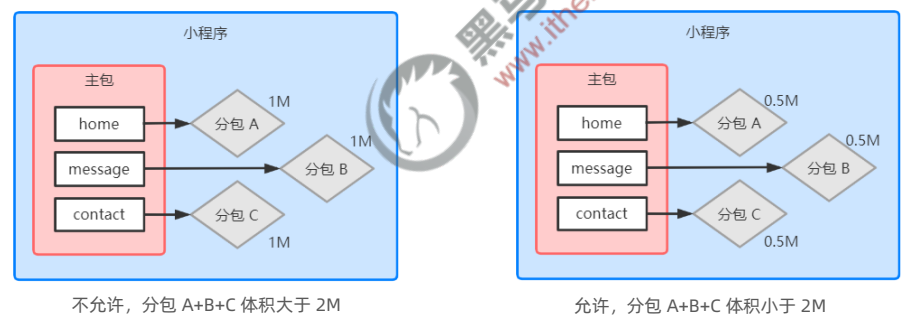

图中 home、message、contact 都在主包中：若分别预下载 A、B、C，每个目标分包 `1M`，总计 `3M`，按课程限额不允许；每个 `0.5M`，合计 `1.5M`，则允许。

这个限制约束“同一个来源包配置的预下载总额”，需要与前面“单包大小”和“整个小程序包大小”分开理解。实际配置时同时检查当前平台限额和包体积。


## 五、自定义 tabBar 案例

案例把 Vant、组件、MobX、监听器和样式覆盖合在一起：底部仍有首页、消息、联系我们，点击后切换页面；消息项的徽标显示共享 `sum`，页面与 numbers 组件改变数值时，徽标一起更新。

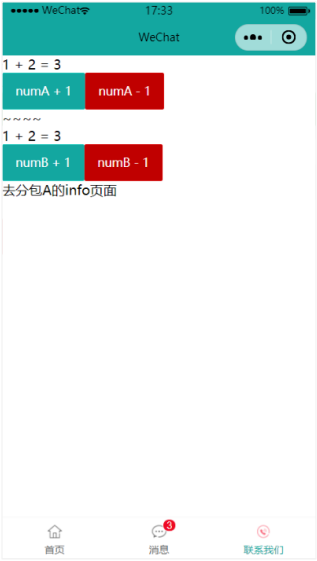

原课把实现分为三大步：配置信息 → 添加 tabBar 代码文件 → 编写代码，并提供[微信自定义 tabBar 文档](https://developers.weixin.qq.com/miniprogram/dev/framework/ability/custom-tabbar.html)。正文没有逐页展示全部实现细节，下面根据配套 `custom-tab-bar` 的完整源码，按这三步拆解。

截图中的分包导航文字属于课件画面，配套完成版 `message.wxml` 没有这条导航；本篇分包练习已另外标明可添加的测试标签。


### 1. 在 app.json 开启自定义 tabBar

在 `app.json.tabBar` 中加入 `custom: true`，仍保留 tabBar 页面配置。配套完整字段：

```json
{
  "tabBar": {
    "custom": true,
    "list": [
      {
        "pagePath": "pages/home/home",
        "text": "首页",
        "iconPath": "/images/tabs/home.png",
        "selectedIconPath": "/images/tabs/home-active.png"
      },
      {
        "pagePath": "pages/message/message",
        "text": "消息",
        "iconPath": "/images/tabs/message.png",
        "selectedIconPath": "/images/tabs/message-active.png"
      },
      {
        "pagePath": "pages/contact/contact",
        "text": "联系我们",
        "iconPath": "/images/tabs/contact.png",
        "selectedIconPath": "/images/tabs/contact-active.png"
      }
    ]
  }
}
```

这三个路径仍需在根级 `pages` 中声明，且全部属于主包。`custom: true` 开启自定义渲染，不替代路由注册。

在根级 `usingComponents` 保留已有按钮与 numbers，并加入两个 Vant 标签：

```json
{
  "usingComponents": {
    "van-button": "@vant/weapp/button/index",
    "my-numbers": "./components/numbers/numbers",
    "van-tabbar": "@vant/weapp/tabbar/index",
    "van-tabbar-item": "@vant/weapp/tabbar-item/index"
  }
}
```

`van-tabbar` 是底部栏，`van-tabbar-item` 是每一项。它们来自本课已经安装并构建的 `@vant/weapp@1.3.3`。


### 2. 添加固定目录与四类文件

在小程序根目录建立 `custom-tab-bar`，文件名固定为 `index`：

```text
custom-tab-bar/
├─ index.js
├─ index.json
├─ index.wxml
└─ index.wxss
```

`custom-tab-bar/index.json` 声明组件：

```json
{
  "component": true,
  "usingComponents": {}
}
```

这是框架通过固定位置加载的自定义 tabBar，不是普通页面文件。无需在每个 tabBar 页面手工插入一个 `<custom-tab-bar>` 标签；先确保目录位于小程序根目录，而不是 `components` 或某个分包内。


### 3. 准备菜单数据并渲染 Vant tabBar

组件 `data.list` 与 `app.json.tabBar.list` 对应，配套源码在消息项额外设置了 `info: 0`。下面是 `custom-tab-bar/index.js` 的菜单数据片段，后面会合并成完整组件：

```javascript
Component({
  data: {
    list: [
      {
        pagePath: '/pages/home/home',
        text: '首页',
        iconPath: '/images/tabs/home.png',
        selectedIconPath: '/images/tabs/home-active.png'
      },
      {
        pagePath: '/pages/message/message',
        text: '消息',
        iconPath: '/images/tabs/message.png',
        selectedIconPath: '/images/tabs/message-active.png',
        info: 0
      },
      {
        pagePath: '/pages/contact/contact',
        text: '联系我们',
        iconPath: '/images/tabs/contact.png',
        selectedIconPath: '/images/tabs/contact-active.png'
      }
    ]
  }
})
```

菜单 `pagePath` 用于后续 `wx.switchTab`，这里带根路径 `/`。图标文件由资料包提供，保留正常图标与选中图标两套路径。

`custom-tab-bar/index.wxml` 的配套模板为：

```xml
<!--custom-tab-bar/index.wxml-->
<van-tabbar active="{{active}}" bind:change="onChange" active-color="#13A7A0">
	<van-tabbar-item wx:for="{{list}}" wx:key="index" info="{{item.info ? item.info : ''}}">
		<image slot="icon" src="{{item.iconPath}}" mode="aspectFit" style="width: 25px; height: 25px;" />
		<image slot="icon-active" src="{{item.selectedIconPath}}" mode="aspectFit" style="width: 25px; height: 25px;" />
		{{item.text}}
	</van-tabbar-item>
</van-tabbar>
```

| 模板部分 | 作用 |
| --- | --- |
| `active="{{active}}"` | 绑定选中索引 |
| `bind:change="onChange"` | 接收 Vant 选择变化事件 |
| `active-color="#13A7A0"` | 设置选中项颜色 |
| `wx:for="{{list}}"` | 按三个菜单项渲染 |
| `slot="icon"`、`slot="icon-active"` | 插入普通和选中图标 |
| `info="{{item.info ? item.info : ''}}"` | 有数值时显示徽标，0 时传空字符串 |

配套使用 `wx:key="index"`，三个菜单位置固定。徽标字段 `info` 属于课程 Vant 版本，本篇按实际依赖保留。


### 4. 先理解选中项和页面跳转

Vant 的 `change` 事件通过 `event.detail` 给出选中项索引：本例首页为 `0`、消息为 `1`、联系我们为 `2`。

组件需要同时更新选中状态并切换页面。配套 `onChange` 放在 `custom-tab-bar/index.js` 的 `methods`：

```javascript
Component({
  methods: {
    onChange(event) {
      // event.detail 的值为当前选中项的索引
      // this.setData({ active: event.detail })
      this.updateActive(event.detail)
      wx.switchTab({
        url: this.data.list[event.detail].pagePath,
      })
    }
  }
})
```

注释中的 `this.setData({ active: event.detail })` 是只改当前组件状态的阶段；完成版调用 `this.updateActive(...)` 修改共享 Store。`wx.switchTab` 使用 `list[event.detail].pagePath` 切换到已经注册的 tabBar 页面。

菜单顺序必须与索引、页面路径一致，否则高亮或跳转会对应错误页面。`updateActive` 的来源在下一节通过 MobX action 绑定。


### 5. 用 Store 共享 tabBar 选中状态

各 tabBar 页面上的自定义 tabBar 需要读到相同的选中索引；只改某一个组件实例的 `active`，不能覆盖整个案例的状态同步。

在 `store/store.js` 保留数值和求和逻辑，增加 `activeTabBarIndex: 0` 与 `updateActiveTabBarIndex`。配套最终 Store 为：

```javascript
// 在这个 JS 文件中，专门来创建 Store 的实例对象
import { observable, action } from 'mobx-miniprogram'

export const store = observable({
  // 数据字段
  numA: 1,
  numB: 2,
  activeTabBarIndex: 0,
  // 计算属性
  get sum() {
    return this.numA + this.numB
  },
  // actions 函数，专门来修改 store 中数据的值
  updateNum1: action(function (step) {
    this.numA += step
  }),
  updateNum2: action(function (step) {
    this.numB += step
  }),
  updateActiveTabBarIndex: action(function(index) {
    this.activeTabBarIndex = index
  })
})
```

在 tabBar 组件使用 `storeBindingsBehavior`，绑定字段与 action：

```javascript
import { storeBindingsBehavior } from 'mobx-miniprogram-bindings'
import { store } from '../store/store'

Component({
  behaviors: [storeBindingsBehavior],
  storeBindings: {
    store,
    fields: {
      sum: 'sum',
      active: 'activeTabBarIndex'
    },
    actions: {
      updateActive: 'updateActiveTabBarIndex'
    }
  }
})
```

`active` 是组件模板使用的字段，来源是 Store 的 `activeTabBarIndex`；`this.updateActive` 是组件方法，映射到 Store 的 `updateActiveTabBarIndex`。这样点击一个菜单项修改 Store 后，其他绑定实例也能接收新的选中状态。


### 6. 监听 sum，更新消息徽标

在 `custom-tab-bar/index.js` 中加入与 `data`、`methods` 同级的 `observers`：

```javascript
Component({
  observers: {
    'sum': function (val) {
      this.setData({
        'list[1].info': val
      })
    }
  }
})
```

绑定层把 Store 的 `sum` 同步到组件后，监听器把新值写入第二项，也就是消息项的 `info`。`'list[1].info'` 是 `setData` 的数组元素属性路径，需要作为完整字符串键使用。

更新链条是：页面或 numbers 按钮 → `updateNum1`/`updateNum2` → Store 数值与 `sum` → tabBar 的绑定字段 → `observers.sum` → `list[1].info` → 徽标显示。

初始 `sum` 为 `3`，消息徽标应显示 `3`；数值改变时徽标更新。`sum` 为 `0` 时，模板条件返回空字符串，所以徽标不显示。


### 7. 调整样式隔离并覆盖 Vant 间距

在 `custom-tab-bar/index.js` 的 `options` 中设置配套样式隔离选项：

```javascript
Component({
  options: {
    styleIsolation: 'shared'
  }
})
```

`custom-tab-bar/index.wxss` 设置：

```css
/* custom-tab-bar/index.wxss */
.van-tabbar-item {
  --tabbar-item-margin-bottom: 0;
}
```

配套 Vant 的 `.van-tabbar-item__icon` 使用 `var(--tabbar-item-margin-bottom, 5px)`，所以把这个变量设为 `0` 可以调整图标下方的间距。本例由外层自定义 tabBar 覆盖 Vant 项的样式范围，需要与 `shared` 设置一起理解。

这是通过组件库支持的 CSS 变量改变表现，修改位置在自己的 `custom-tab-bar/index.wxss`，不直接改生成的 `miniprogram_npm` 文件。重新编译后检查图标和文字的排布。


### 8. 对照完整 tabBar 组件

前面几节解释了每个节点，合并后 `custom-tab-bar/index.js` 的配套完整代码为：

```javascript
// custom-tab-bar/index.js
import { storeBindingsBehavior } from 'mobx-miniprogram-bindings'
import { store } from '../store/store'

Component({
  options: {
    styleIsolation: 'shared'
  },
  behaviors: [storeBindingsBehavior],
  storeBindings: {
    store,
    fields: {
      sum: 'sum',
      active: 'activeTabBarIndex'
    },
    actions: {
      updateActive: 'updateActiveTabBarIndex'
    },
  },
  observers: {
    'sum': function (val) {
      this.setData({
        'list[1].info': val
      })
    }
  },
  /**
   * 组件的属性列表
   */
  properties: {

  },

  /**
   * 组件的初始数据
   */
  data: {
    "list": [
      {
        "pagePath": "/pages/home/home",
        "text": "首页",
        "iconPath": "/images/tabs/home.png",
        "selectedIconPath": "/images/tabs/home-active.png"
      },
      {
        "pagePath": "/pages/message/message",
        "text": "消息",
        "iconPath": "/images/tabs/message.png",
        "selectedIconPath": "/images/tabs/message-active.png",
        info: 0
      },
      {
        "pagePath": "/pages/contact/contact",
        "text": "联系我们",
        "iconPath": "/images/tabs/contact.png",
        "selectedIconPath": "/images/tabs/contact-active.png"
      }
    ]
  },

  /**
   * 组件的方法列表
   */
  methods: {
    onChange(event) {
      // event.detail 的值为当前选中项的索引
      // this.setData({ active: event.detail })
      this.updateActive(event.detail)
      wx.switchTab({
        url: this.data.list[event.detail].pagePath,
      })
    },
  }
})
```

保留 `data.list`、`storeBindings`、`observers`、`options` 与 `methods` 的相对位置；组件方法在 `methods` 中，MobX 配置和监听器与它同级。不要为了合并片段而在同一对象中写两份 `data` 或两份 `methods`。


### 9. 按操作顺序验证案例

1. **依赖和配置**：确认已构建 npm、引用两个 Vant tabBar 组件，`custom: true` 已加入，三个菜单路径都在主包的 `pages` 中。
2. **界面**：从默认首页启动，底部显示三个菜单项，正常图标和选中图标使用配套图片。
3. **切换**：依次点击消息、联系我们、首页，检查页面与高亮项一致；这是本课由 tabBar 点击驱动的路径。
4. **共享数值**：在消息页操作 `numA` 与 `numB` 按钮，页面、numbers 组件两组等式应保持一致。
5. **徽标**：消息项显示 `sum`，改变数值后更新；减到 0 时，徽标按模板条件隐藏。
6. **清理**：修正消息页的 `destroyStoreBindings` 拼写，页面实际卸载时清理绑定；切换 tabBar 只隐藏页面，不等同于卸载。
7. **分包**：确认 `pkgA` 为普通分包、`pkgB` 为独立分包，“联系我们”页面的 Wi-Fi 规则预下载 `p1`。

源码边界：初始 `activeTabBarIndex` 固定为 `0`，完成版只在组件 `onChange` 中更新索引，三个页面的 `onShow` 没有同步处理。若直接以消息页启动，或从其他代码调用 `wx.switchTab` 而不更新 Store，当前源码可能出现选中项与页面不一致。验证课程点击流程时从首页开始；不要把这一实现当成已覆盖全部外部跳转入口。

本篇保留课程完整实现与必要源码校对，没有在微信开发者工具中实际运行接口、分包或 tabBar。以上均为配套练习的预期验证结果。


## 六、原课学习目标

| 第 05 天目标 | 对应关键操作 |
| --- | --- |
| 安装和配置 Vant Weapp | 指定版本安装、构建 npm、`usingComponents`、主题变量 |
| 使用 MobX 共享数据 | `observable`、`action`、页面手工绑定、组件 behavior 绑定 |
| 对小程序 API 进行 Promise 化 | `miniprogram-api-promise`、`promisifyAll`、`wx.p.request` |
| 实现自定义 tabBar | `custom: true`、固定组件目录、Vant 菜单、Store 索引、`sum` 徽标 |

正文还完整讲了分包：主包与分包的加载和引用边界、`subpackages`、独立分包的 `independent`，以及 `preloadRule` 的网络条件和共享限额。这些配置与 tabBar 的页面路由放在同一个 `app.json` 中，修改时合并字段，不覆盖已有配置。
